Saving pearls.png to pearls.png


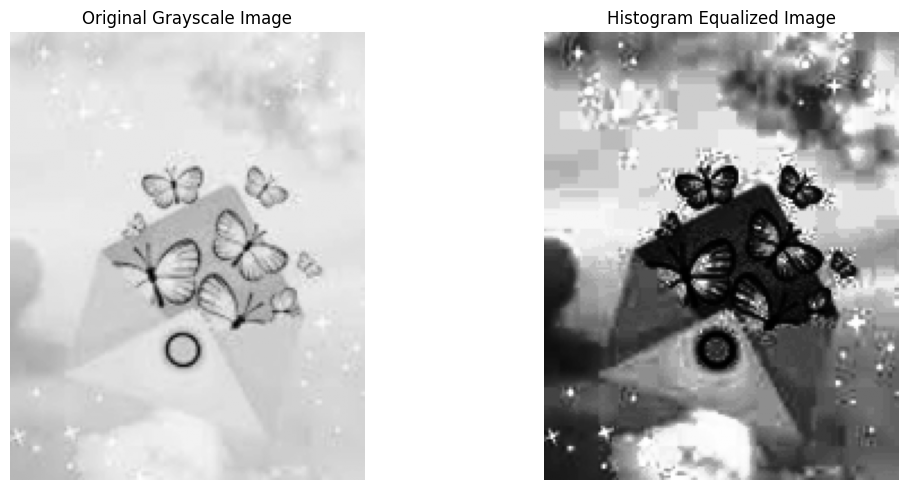

In [3]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# Upload image
uploaded = files.upload()

# Get uploaded filename
filename = next(iter(uploaded))

# Read image in grayscale
image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# Apply Histogram Equalization
equalized_image = cv2.equalizeHist(image)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized_image, cmap='gray')
plt.title("Histogram Equalized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Upload the INPUT image:


Saving pearls.png to pearls (1).png
Upload the REFERENCE image:


Saving Screenshot 2026-10-21 195635.png to Screenshot 2026-10-21 195635.png


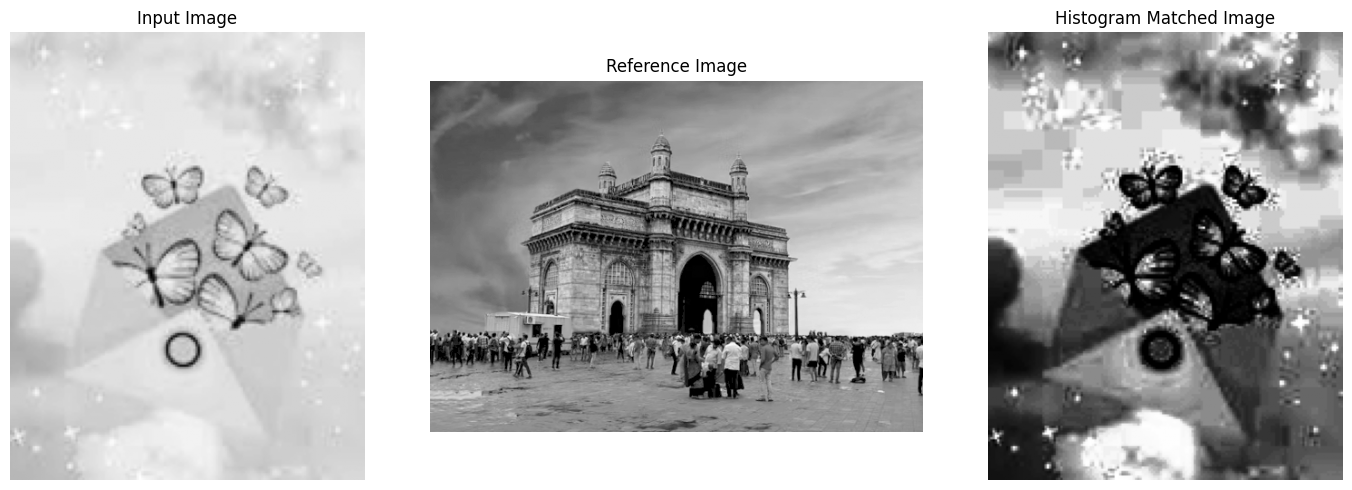

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload input image
print("Upload the INPUT image:")
uploaded_input = files.upload()
input_filename = next(iter(uploaded_input))

# Upload reference image
print("Upload the REFERENCE image:")
uploaded_reference = files.upload()
reference_filename = next(iter(uploaded_reference))

# Read both images in grayscale
input_image = cv2.imread(input_filename, cv2.IMREAD_GRAYSCALE)
reference_image = cv2.imread(reference_filename, cv2.IMREAD_GRAYSCALE)

# Histogram Equalization
input_equalized = cv2.equalizeHist(input_image)
reference_equalized = cv2.equalizeHist(reference_image)

# Histogram Matching
# Calculate CDF of input and reference images
input_hist, _ = np.histogram(input_equalized.flatten(), 256, [0, 256])
reference_hist, _ = np.histogram(reference_equalized.flatten(), 256, [0, 256])

input_cdf = input_hist.cumsum()
reference_cdf = reference_hist.cumsum()

# Normalize CDF
input_cdf = input_cdf / input_cdf[-1]
reference_cdf = reference_cdf / reference_cdf[-1]

# Create mapping
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    mapping[i] = np.argmin(np.abs(reference_cdf - input_cdf[i]))

# Apply mapping to input image
matched_image = mapping[input_equalized]

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_image, cmap='gray')
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_image, cmap='gray')
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched_image, cmap='gray')
plt.title("Histogram Matched Image")
plt.axis("off")

plt.tight_layout()
plt.show()